In [40]:
import numpy as np
from scipy import linalg as la
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
np.set_printoptions(precision=3, suppress=True)

#####
<font color="#2c3e50" size="6"><div style="
    font-family: sans-serif;
    font-size: 1.2em;
    font-weight: 700;
    line-height: 1.2;
    background-color: #d9e6f2;
    border-radius: 8px;
    border-top: 2px solid rgba(144,62,80,0.3);
    border-bottom: 2px solid rgba(144,62,80,0.3);
    padding: 0.5em 1em;
    margin-top: 1em;
    margin-bottom: 0.6em;
    box-shadow: 0 2px 6px rgba(0,0,0,0.1);
" align="center">
4.4 Least-Squares Approximation
</div></font>

######
<font color="#3f7fff" size="5"><div style="
    font-family: Verdana;
    font-size: 1.6em;
    font-weight: 600;
    line-height: 1.3;
    padding: 0.5em 1em;
    margin: 0.5em 0 0.6em 0;
    border-top: 2px solid rgba(144,62,80,0.3);
    border-bottom: 2px solid rgba(144,62,80,0.3);
    border-radius: 8px;
">
<b>Best Approximation</b>
</div></font> 

In many branches of science, we use experimental data to infer the relationship between various variables. For example, we might collect data showing sales collected throughout the year over multiple years and try to deduce monthly trends - the relationship between the month and the number of sales we expect to have. In this example, the month is the independent variable, and the number of sales is the dependent variable. We would like to find a function that best approximates the relationship between these two variables. The next figure shows a few examples of data together with curves that approximate the data. Notice that the curves do not necessarily pass through all of the data points.

<center> <img src="data:image/png;base64,  ...
 " width="80%"> </center>

Typically, we first decide what type of function we would like to use for the approximation (linear, quadratic, exponential, etc.). Once the model has been chosen, we then determine the specific function of that type that best fits the data. In this course, we will only focus on the second part.

Typically, these types of problems are reduced to finding the vector $\bf w$ in a subspace $W$ of $\mathbb{R}^n$ that is closest to a given vector $\bf v$ in $\mathbb{R}^n$.

<div style="
    font-family: Verdana, sans-serif;
    font-size: 14px;
    line-height: 1.6;
    margin: 0.8em 0;
    padding: 0.75em 1em;
    border-radius: 6px;
    border-left: 4px solid #2c3e50;
    border-left-color: #55a868;
    background-color: rgba(10,150,50,0.16);
    margin: 0.4em 0;
">
<strong>🏛️ Theorem</strong><br> Let $W$ be a subspace of $\mathbb{R}^n$ and let $\bf v$ be any vector in $\mathbb{R}^n$. Let $\hat{\bf v}=proj_W({\bf v})$ be the orthogonal projection of $\bf v$ onto $W$. Then $\hat{\bf v}$ is point in $W$ closest to $\bf v$. In other words, for every vector $\bf w$ in $W$ distinct from  $\hat{\bf v}$, $$||{\bf v}-\hat{\bf v}||<||{\bf v}-{\bf w}||$$
The vector $\hat{\bf v}$ is called <strong>the best approximation of $\bf v$ in $W$ </strong>.
</div>


**Proof.**

Since $\bf w$ and $\hat{\bf v}$ are both in $W$, the vector $\hat{\bf v}-{\bf w}$ is also in $W$. The vector ${\bf v}-\hat{\bf v}$ is orthogonal to $W$, and therefore it is orthogonal to $\hat{\bf v}-{\bf w}$ (see the figure below).

<center> <img src="data:image/png;base64,  ...
 " width="40%"> </center>

By the Pythagorean Theorem, we get $$\color{blue}{||{\bf v}-\hat{\bf v}||^2}\color{black}{+}\color{green}{||\hat{\bf v}-{\bf w}||^2}\color{black}{=||({\bf v}-\hat{\bf v})+(\hat{\bf v}-{\bf w})||^2=}\color{red}{||{\bf v}-{\bf w}||^2}$$

However, since ${\bf w} \neq \hat{\bf v}$, $||\hat{\bf v}-{\bf w}||^2>0$, and so 
$$ ||{\bf v}-\hat{\bf v}||^2<||{\bf v}-{\bf w}||^2$$

Hence,

$$ ||{\bf v}-\hat{\bf v}||<||{\bf v}-{\bf w}||$$

---
**<font color="red">Example 1</font>**

Let ${\bf v}=\begin{bmatrix} 1 \\ 2 \\ 2 \end{bmatrix}$, ${\bf u}_1=\begin{bmatrix} 1 \\ 0 \\ 2 \end{bmatrix}$ and ${\bf u}_2=\begin{bmatrix} 2 \\ -1 \\ -1 \end{bmatrix}$. Find the best approximation of $\bf v$ in the subspace $W=span({\bf u}_1, {\bf u}_2)$. Then find the distance from ${\bf v}$ to $W$.

**Solution.**

Since  ${\bf u}_1$ and  ${\bf u}_2$ are orthogonal, we can easily find the projection of $\bf v$ onto $W$:

$$proj_W({\bf v})=\frac{{\bf v} \cdot {\bf u}_1}{{\bf u}_1 \cdot {\bf u}_1}{\bf u}_1+\frac{{\bf v} \cdot {\bf u}_2}{{\bf u}_2 \cdot {\bf u}_2}{\bf u}_2=\frac{5}{5}\begin{bmatrix}1 \\ 0 \\ 2 \end{bmatrix}+\frac{-2}{6}\begin{bmatrix} 2 \\ -1 \\ -1 \end{bmatrix}=\begin{bmatrix} 1/3 \\ 1/3 \\ 7/3 \end{bmatrix}$$

The distance from ${\bf v}$ to $W$ is $||{\bf v}-proj_W({\bf v})||$. Therefore,

$${\bf v}-proj_W({\bf v})=\begin{bmatrix} 1 \\ 2 \\ 2 \end{bmatrix}-\begin{bmatrix} 1/3 \\ 1/3 \\ 7/3 \end{bmatrix}=\begin{bmatrix} 2/3 \\ 5/3 \\ -1/3 \end{bmatrix}$$

$$||{\bf v}-proj_W({\bf v})||= \sqrt{\frac{4}{9}+\frac{25}{9}+\frac{1}{9}}=\sqrt{\frac{30}{9}}=\sqrt{\frac{10}{3}}$$


######
<font color="#3f7fff" size="5"><div style="
    font-family: Verdana;
    font-size: 1.6em;
    font-weight: 600;
    line-height: 1.3;
    padding: 0.5em 1em;
    margin: 0.5em 0 0.6em 0;
    border-top: 2px solid rgba(144,62,80,0.3);
    border-bottom: 2px solid rgba(144,62,80,0.3);
    border-radius: 8px;
">
<b>Least-Squares Approximation</b>
</div></font>  

In the remainder of this chapter, we will use the notation commonly used in statistics.

Suppose our dataset consists of three points: $(1,1)$, $(2,2)$ and $(3,2)$; and suppose we think that the $x$ and $y$ values of our measurements are related by a linear function. In other words, we think that all points lie on the line $y=\beta_0+\beta_1x$. In this case, all three points must satisfy this equation of the line which gives us the following system of equations:

$$\left\{\begin{array}{l}
  \beta_0+\beta_1\cdot 1 &=& 1 \\
  \beta_0+\beta_1\cdot 2 &=& 2 \\
  \beta_0+\beta_1\cdot 3 &=& 2
\end{array}\right.$$

Or, in matrix form:

$$\begin{bmatrix} 1 & 1 \\ 1 & 2 \\ 1 & 3\end{bmatrix} \begin{bmatrix} \beta_0 \\ \beta_1 \end{bmatrix} = \begin{bmatrix} 1 \\ 2 \\2 \end{bmatrix}$$

However, this system is inconsistent. This shouldn't be surprising. If you plot the three points, you will see that it is impossible to draw a straight line passing through all three of them. Therefore, our task is to find he line that best fits the points.

For any given line, we can measure how far it is from each data point vertically. This quantity is called the **residual**, or **error**, in the $y$-direction. Let $\epsilon_1$, $\epsilon_2$ and $\epsilon_3$ denote residuals for our points. 

<center> <img src="data:image/png;base64,  ...
 " width="40%"> </center>

We define the **residual vector** as the vector consisting of all residuals.
$${\boldsymbol{\epsilon}}=\begin{bmatrix} \epsilon_1 \\ \epsilon_2 \\\epsilon_3 \end{bmatrix}$$


There are several ways to minimize the error. The most common approach is to minimize the sum of squared residuals, which is equivalent to minimizing the square of the norm of the residual vector. In other words, we want $||{\boldsymbol{\epsilon}}||^2 = \epsilon_1^2+\epsilon_2^2+\epsilon_3^2$ to be as small as possible. This explains where the term "least-squares" comes from. Since minimizing $||{\boldsymbol{\epsilon}}||^2$ is equivalent to minimizing $||{\boldsymbol{\epsilon}}||$, either approach gives the same solution. In this course, we will refer to $||{\boldsymbol{\epsilon}}||$ as the **total error**.

<div style="
    font-family: Verdana, sans-serif;
    font-size: 14px;
    line-height: 1.6;
    margin: 0.8em 0;
    padding: 0.75em 1em;
    border-radius: 6px;
    border-left: 4px solid #2c3e50;
    border-left-color: #4c72b0;
    background-color: rgba(10,150,250,0.16);
    margin: 0.4em 0;
">
<strong>📌 Note:</strong> It might be tempting to minimize $|\epsilon_1|+|\epsilon_2|+|\epsilon_3|$ instead. However, absolute values can be more difficult to work with and minimizing the sum of squared residuals leads to more convenient formulas. 
</div> 

It is straightforward to calculate the residuals for any given line. For example, for our three points we obtain

$$\epsilon_1 = 1 - ( \beta_0+\beta_1\cdot 1)$$
$$\epsilon_2 = 2 - ( \beta_0+\beta_1\cdot 2)$$
$$\epsilon_3 = 2 - ( \beta_0+\beta_1\cdot 3)$$

---

**<font color="red">Example 2</font>**

For the data points $(1,1)$, $(2,2)$ and $(3,2)$, which line has the smaller least-squares error: $y=x$ or $ y=x-1/3$?

**Solution**

For $y=x$, we get

$$\epsilon_1 = 1 - (  1)=0$$
$$\epsilon_2 = 2 - (  2)=0$$
$$\epsilon_3 = 2 - (  3)=-1$$

Therefore, $||{\boldsymbol{\epsilon}}||= \sqrt{0+0+1}=1$

For $y=x-1/3$, we get

$$\epsilon_1 = 1 - ( -1/3+1)=1/3$$
$$\epsilon_2 = 2 - ( -1/3+ 2)=1/3$$
$$\epsilon_3 = 2 - ( -1/3 + 3)=-2/3$$

Therefore, $||{\boldsymbol{\epsilon}}||= \sqrt{1/9+1/9+4/9}=\sqrt{6/9} \approx 0.82$

Hence, $y=x-1/3$ is a better approximation than $y=x$, even though it does not pass through any of the data points, while $y=x$ passes through two of them.

---

While $y=x-1/3$ is a better fit than $y=x$ in the previous example, we still do not know whether an even better line exists. Before answering this question, let's organize our results.

Suppose we have data points $(x_1, y_1), \cdots, (x_n, y_n)$ that we would like to approximate with a line $y=\beta_0+\beta_1 x$. We want each data point to satisfy the line equation, and so for each $i=1, \cdots , n$, we want $\beta_0+\beta_1 x_i = y_i$ leading to the following matrix equation
$$X{\boldsymbol{\beta}}={\bf y},$$

where $$X=\begin{bmatrix} 1 & x_1 \\ 1 & x_2 \\ \vdots & \vdots \\ 1 & x_n \end{bmatrix} \text{, }  {\boldsymbol{\beta}}=\begin{bmatrix} \beta_0 \\ \beta_1 \end{bmatrix} \text{, and } {\bf y}=\begin{bmatrix} y_1\\ y_2 \\ \vdots \\ y_n\end{bmatrix}$$

If this equation is consistent, then the solution defines the line going through every point (In this case, total error is equal to zero). However, normally this equation is not consistent. In this case, we would like to find ${\boldsymbol{\beta}}$ that minimizes the total error. In either case, we call such a line a best-fit line or a regression line. 

Each error is given by 
$$\epsilon_i=y_i-(\beta_0+\beta_1x_i)$$

The residual vector can be written as

$${\boldsymbol{\epsilon}}={\bf y}- X{\boldsymbol{\beta}}$$

We would like to find ${\boldsymbol{\beta}}$ that minimizes $||{\boldsymbol{\epsilon}}||= ||{\bf y}- X{\boldsymbol{\beta}}||$.

<div style="
    font-family: Verdana, sans-serif;
    font-size: 14px;
    line-height: 1.6;
    margin: 0.8em 0;
    padding: 0.75em 1em;
    border-radius: 6px;
    border-left: 4px solid #2c3e50;
    border-left-color: #55a868;
    background-color: rgba(10,150,50,0.16);
    margin: 0.4em 0;
">
<strong>🏛️ Definition</strong><br> If $X$ is an $m \times n$ matrix and ${\bf y}$ is a vector in $\mathbb{R}^m$, a <strong>least-squares solution</strong> of $X{\boldsymbol{\beta}}={\bf y}$ is a vector $\hat{\boldsymbol{\beta}}$ in $\mathbb{R}^n$ such that 

$$||{\bf y}- X\hat{\boldsymbol{\beta}}|| \leq ||{\bf y}- X{\boldsymbol{\beta}}||$$

for every ${\boldsymbol{\beta}}$ in $\mathbb{R}^n$.
</div>


An important observation about least-squares approximation is that for any vector ${\boldsymbol{\beta}}$, the vector $X{\boldsymbol{\beta}}$ lies in the column space of $X$ and therefore, we are looking for a vector that makes $X{\boldsymbol{\beta}}$ the closest point in $Col(X)$ to $\bf y$. Hence, if $\hat{\boldsymbol{\beta}}$ is the least-squares solution to $X{\boldsymbol{\beta}}={\bf y}$, then 
$$X\hat{\boldsymbol{\beta}}=proj_{Col(X)}({\bf y})$$

To calculate the orthogonal projection above, we normally need to know the basis of the subspace. However, in order to avoid looking for a basis for $Col(X)$, we note that the vector ${\bf y}-X\hat{\boldsymbol{\beta}}={\bf y}-proj_{Col(X)}({\bf y})$ is orthogonal to $Col(X)$. Since the orthogonal complement of $Col(X)$ is $Nul(X^T)$, then the vector ${\bf y}-X\hat{\boldsymbol{\beta}}$ is in $Nul(X^T)$ and therefore

$$X^T({\bf y}-X\hat{\boldsymbol{\beta}})={\bf 0}$$
$$X^T{\bf y}-X^TX\hat{\boldsymbol{\beta}}={\bf 0}$$
$$X^TX\hat{\boldsymbol{\beta}}=X^T{\bf y}$$

The last matrix equation represents a system of linear equations called **normal equations** for $X{\boldsymbol{\beta}}={\bf y}$

<div style="
    font-family: Verdana, sans-serif;
    font-size: 14px;
    line-height: 2;
    margin: 0.8em 0;
    padding: 0.75em 1em;
    border-radius: 6px;
    border-left: 4px solid #2c3e50;
    border-left-color: #55a868;
    background-color: rgba(10,150,50,0.16);
    margin: 0.4em 0;
">
<strong>🏛️ Theorem</strong><br> <span style="line-height: 1.5; display: inline-block;">Let $X$ be an $m \times n$ matrix and let ${\bf y}$ be in $\mathbb{R}^m$. Then $X{\boldsymbol{\beta}}={\bf y}$ always has at least one least-squares solution $\hat{\boldsymbol{\beta}}$. Moreover, </span><br>

<span style="line-height: 1.5; display: inline-block;"><strong>1.</strong> The vector $\hat{\boldsymbol{\beta}}$ is a least-square solution of $X{\boldsymbol{\beta}}={\bf y}$ if and only if $\hat{\boldsymbol{\beta}}$ is a solution to the normal equations $X^TX{\boldsymbol{\beta}}=X^T{\bf y}$</span><br>
<span style="line-height: 1.5; display: inline-block;"><strong>2.</strong> The matrix $X$ has linearly independent columns if and only if $X^TX$ is invertible. In this case, the least-square solution is unique and is given by</span>
 $$\hat{\boldsymbol{\beta}}=(X^TX)^{-1}X^T{\bf y}$$
</div>

<div style="
    font-family: Verdana, sans-serif;
    font-size: 14px;
    line-height: 1.6;
    margin: 0.8em 0;
    padding: 0.75em 1em;
    border-radius: 6px;
    border-left: 4px solid #2c3e50;
    border-left-color: #4c72b0;
    background-color: rgba(10,150,250,0.16);
    margin: 0.4em 0;
">
<strong>📌 Note:</strong> If the columns of $X$ are linearly dependent, then there may be more than one least-squares solution.
</div> 


**<font color="red">Example 3</font>**

For the data points $(1,1)$, $(2,2)$ and $(3,2)$, find the best-fit line and compute the total error.

**Solution.**

We begin by defining $X$ and ${\bf y}$:

$$X=\begin{bmatrix} 1 & 1 \\ 1 & 2 \\ 1 & 3\end{bmatrix}, {\bf y}=\begin{bmatrix} 1 \\ 2 \\2 \end{bmatrix}$$

Then,

$$X^TX=\begin{bmatrix}3 & 6 \\ 6 & 14 \end{bmatrix}\text{, and } X^T{\bf y}=\begin{bmatrix} 5 \\11  \end{bmatrix}$$

Solving $X^TX{\bf b}=X^T{\bf y}$ gives the solution

$$\hat{\boldsymbol{\beta}}=\begin{bmatrix} 2/3 \\ 1/2 \end{bmatrix}$$

Therefore, the best-fit line is $$y=\frac{2}{3} + \frac{1}{2} x$$

Next, we calculate the error terms:

$$\epsilon_1 = 1 - \left( \frac{2}{3}+\frac{1}{2}\cdot 1 \right)=-1/6$$
$$\epsilon_2 = 2 - \left( \frac{2}{3}+\frac{1}{2}\cdot 2 \right)=1/3$$
$$\epsilon_3 = 2 - \left( \frac{2}{3}+\frac{1}{2}\cdot 3 \right)=-1/6$$

Therefore, $||\hat{\boldsymbol{\epsilon}}||= \sqrt{1/36+1/9+1/36}=\sqrt{1/6} \approx 0.4$

Here is how the regression line $y=\frac{2}{3} + \frac{1}{2} x$ found here compares to the line $y=-\frac{1}{3} +  x$ we considered before.

<center> <img src="data:image/png;base64,  ...
 " width="40%"> </center>

---

**<font color="red">Example 4</font>**

Find the best-fit line and compute the total error for the following data points: $(3,4), (4,4), (1.5,3), (2,4), (3.5,4.5)$. Then plot the points and the line.

**Solution.**

In [62]:
x=np.array([3,4,1.5,2,3.5])
y=np.array([4,4,3,4,4.5])
X=np.array([x**0, x]).T
print(X)

[[1.  3. ]
 [1.  4. ]
 [1.  1.5]
 [1.  2. ]
 [1.  3.5]]


In [63]:
line=la.solve(X.T@X,X.T@y)
print(f'Coefficients of the line: {line}')

Coefficients of the line: [2.826 0.384]


So, the equation of the line is approximately $y=2.8256+0.3837x$. 

To find the total error, we need to subtract predicted $y$-values from the observed $y$-values (the ones given to us), and then find the norm of the resulting vector. We can calculate the predicted values using NumPy's element-wise array operations and broadcasting.

In [64]:
y_pred=line[0]+line[1]*x
print(f'Predicted values: {y_pred}')

Predicted values: [3.977 4.36  3.401 3.593 4.169]


In [65]:
print(f'Total error = {la.norm(y-y_pred):.3f}')

Total error = 0.753


Now, let's plot the data points and the regression line.

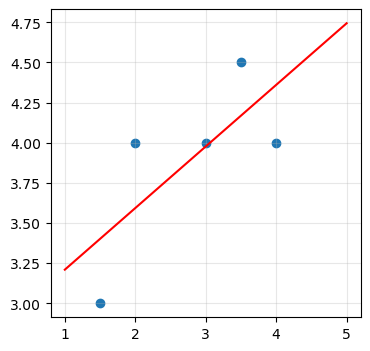

In [66]:
plt.subplots(figsize=(4,4))
xl=np.linspace(1,5,100) 
yl=line[0]+line[1]*xl
plt.plot(xl,yl,'-r')
plt.scatter(x,y)
plt.grid(alpha=0.3)
plt.show()

<div style="
    font-family: Verdana, sans-serif;
    font-size: 14px;
    line-height: 1.6;
    margin: 0.8em 0;
    padding: 0.75em 1em;
    border-radius: 6px;
    border-left: 4px solid #2c3e50;
    border-left-color: #4c72b0;
    background-color: rgba(10,150,250,0.16);
    margin: 0.4em 0;
">
<strong>📌 Note:</strong> The magnitude of the error depends on the scale of the data. You cannot say that the error we got is large or small on its own. It is most useful for comparing different models fitted to the same dataset.
</div> 

---

Let's apply this to a larger dataset. In Chapter 1.3, we created a dataset about penguins and looked at the relationship between flipper length and body mass using the Seaborn's `jointplot` function. Let's now compute the regression line using the methods from this chapter.

It is common practice to standardize the data before performing regression. As a reminder, this means for each feature, we subtract the mean and divide by the standard deviation.

---
**<font color="red">Example 5</font>**

Upload the `Penguins_map.csv` file. Extract the flipper length and body mass variables, standardize the data and find the linear regression line for predicting body mass. 

**Solution.**


In [67]:
df=pd.read_csv('Penguins_map.csv')
df.head()

,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181,3750,0
1,Adelie,Torgersen,39.5,17.4,186,3800,1
2,Adelie,Torgersen,40.3,18.0,195,3250,1
3,Adelie,Torgersen,36.7,19.3,193,3450,1
4,Adelie,Torgersen,39.3,20.6,190,3650,0


In [68]:
x=df['flipper_length_mm'].to_numpy()
y=df['body_mass_g'].to_numpy()

x=(x-x.mean())/(x.std())
y=(y-y.mean())/(y.std())

X=np.array([x**0, x]).T

line=la.solve(X.T@X,X.T@y)
print(f'Coefficients of the line: {line}')

Coefficients of the line: [-0.     0.873]


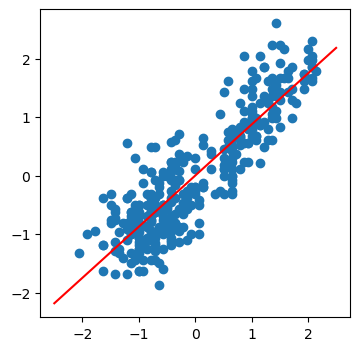

In [70]:
plt.subplots(figsize=(4,4))
xl=np.linspace(-2.5,2.5,100) 
yl=line[0]+line[1]*xl
plt.plot(xl,yl,'-r')
plt.scatter(x,y)
plt.show()

Compare it to what we got with jointplot in Chapter 1.3.

######
<font color="#3f7fff" size="5"><div style="
    font-family: Verdana;
    font-size: 1.6em;
    font-weight: 600;
    line-height: 1.3;
    padding: 0.5em 1em;
    margin: 0.5em 0 0.6em 0;
    border-top: 2px solid rgba(144,62,80,0.3);
    border-bottom: 2px solid rgba(144,62,80,0.3);
    border-radius: 8px;
">
<b> QR Factorization Method</b>
</div></font>

Solving the normal equations can introduce numerical inaccuracies due to floating-point rounding errors. In practice, we often use alternative methods. For instance, QR factorization provides a more numerically stable approach.

<div style="
    font-family: Verdana, sans-serif;
    font-size: 14px;
    line-height: 1.6;
    margin: 0.8em 0;
    padding: 0.75em 1em;
    border-radius: 6px;
    border-left: 4px solid #2c3e50;
    border-left-color: #55a868;
    background-color: rgba(10,150,50,0.16);
    margin: 0.4em 0;
">
<strong>🏛️ Theorem</strong><br> Let $X$ be an $m \times n$ matrix with linearly independent columns and let $X=QR$ be a QR factorization of $X$. Then, for every $\bf y$ in $\mathbb{R}^m$, the equation $X{\boldsymbol{\beta}}={\bf y}$ has a unique least-squares solution given by $$\hat{\boldsymbol{\beta}}=R^{-1}Q^T{\bf y}$$
</div>



**Proof.**

The vector $\hat{\boldsymbol{\beta}}$ satisfies the normal equations. Therefore,
$$X^TX\hat{\boldsymbol{\beta}}=X^T{\bf y}$$

Since $X=QR$, we get

$$ (QR)^TQR\hat{\boldsymbol{\beta}}=(QR)^T{\bf y}$$
$$R^TQ^TQR\hat{\boldsymbol{\beta}}=R^TQ^T{\bf y}$$

Since $Q$ has orthonormal columns,
$$R^TR\hat{\boldsymbol{\beta}}=R^TQ^T{\bf y}$$
Since $R$ is invertible, $R^T$ is also invertible. Multiplying both sides by the inverse of $R^T$ gives 
$$R\hat{\boldsymbol{\beta}}=Q^T{\bf y}$$
or equivalently,
$$\hat{\boldsymbol{\beta}}=R^{-1}Q^T{\bf y}$$


<div style="
    font-family: Verdana, sans-serif;
    font-size: 14px;
    line-height: 1.6;
    margin: 0.8em 0;
    padding: 0.75em 1em;
    border-radius: 6px;
    border-left: 4px solid #2c3e50;
    border-left-color: #4c72b0;
    background-color: rgba(10,150,250,0.16);
    margin: 0.4em 0;
">
<strong>📌 Note:</strong> In practice, it is better to solve $R{\boldsymbol{\beta}}=Q^T{\bf y}$ to find $\hat{\boldsymbol{\beta}}$ using back substitution rather than explicitly computing $R^{-1}$.
</div> 

---

**<font color="red">Example 6</font>**

Let $X=\begin{bmatrix} 1 & 1 & 0 \\ 2 & 5 & -1 \\ 0 & 1 & 2 \\ 1 & 1 & 1 \\ 2 & 0 & 3 \end{bmatrix}$ and ${\bf y}=\begin{bmatrix} 10 \\ 1 \\2 \\3 \\4\end{bmatrix}$. Find the least-squares solution to $X{\boldsymbol{\beta}}={\bf y}$ using Python.

**Solution.**

We will solve this problem in four different ways.

In [50]:
X=np.array([[1,1,0],[2,5,-1],[0,1,2],[1,1,1],[2,0,3]])
y=np.array([10,1,2,3,4])

**Method 1:** The solution is given by $ \hat{\boldsymbol{\beta}}=(X^TX)^{-1}X^T{\bf y}$.

In [51]:
b=la.inv(X.T@X)@X.T@y
print(b)

[ 2.657 -0.406  0.26 ]


**Method 2:** Avoid computing the inverse by solving $ X^TX{\boldsymbol{\beta}}=X^T{\bf y}$.

In [52]:
b=la.solve(X.T@X,X.T@y)
print(b)

[ 2.657 -0.406  0.26 ]


**Method 3:** QR factorization. The solution is given by $\hat{\boldsymbol{\beta}}=R^{-1}Q^T{\bf y}$. This method is generally more numerically stable than solving the normal equations.

In [53]:
Q, R = np.linalg.qr(X)
b=la.inv(R)@Q.T@y
print(b)

[ 2.657 -0.406  0.26 ]


**Method 4:** QR factorization without explicitly computing the inverse.

In [54]:
Q, R = np.linalg.qr(X)
b=la.solve(R,Q.T@y)
print(b)

[ 2.657 -0.406  0.26 ]


######
<font color="#3f7fff" size="5"><div style="
    font-family: Verdana;
    font-size: 1.6em;
    font-weight: 600;
    line-height: 1.3;
    padding: 0.5em 1em;
    margin: 0.5em 0 0.6em 0;
    border-top: 2px solid rgba(144,62,80,0.3);
    border-bottom: 2px solid rgba(144,62,80,0.3);
    border-radius: 8px;
">
<b>Nonlinear Regression</b>
</div></font> 

In machine learning, we try to discover the relationship between a set of input measurements (independent variables) and an outcome (dependent variable) so that we can predict the outcome for new inputs. Regression problems are those in which the outcome is continuous. The regression line obtained in Example 4 is one example.

However, the relationship doesn't have to be linear. It may be quadratic, exponential, or another nonlinear function. We may also have multiple independent variables or multiple dependent variables.

Note that while the functions may be nonlinear in their input variables, they are linear in their unknown coefficients. Therefore, we can still apply the same linear least-squares methods.

---
**<font color="red">Example 7</font>**

Approximate the following data with a quadratic curve using the least-squares method: $(3,4.5), (4,4), (1.5,3), (2,4), (3.5,4.5)$.

**Solution.**

A quadratic curve has an equation of the form $$y=\beta_0+\beta_1x+\beta_2x^2$$
So, if we have a collection of data points $(x_1, y_1),\cdots,(x_n, y_n)$, we want them to satisfy

$$\begin{bmatrix} 1 & x_1 & x_1^2 \\ 1 & x_2 & x_2^2 \\ \vdots & \vdots & \vdots \\ 1 & x_n & x_n^2 \end{bmatrix} \begin{bmatrix} \beta_0 \\ \beta_1 \\ \beta_2 \end{bmatrix} = \begin{bmatrix} y_1 \\ y_2 \\ \vdots \\ y_n\end{bmatrix} \Rightarrow  X{\boldsymbol{\beta}}={\bf y}$$

Therefore, the matrix $X$ must be modified to incorporate quadratic terms. As before, the resulting system will generally be inconsistent and so we want to minimize the norm of the residual vector. However, from a linear algebra point of view, it is the same problem as before.

In [71]:
x=np.array([3,4,1.5,2,3.5])
y=np.array([4.5,4,3,4,4.5])
X=np.array([x**0, x, x**2]).T
print(X)

[[ 1.    3.    9.  ]
 [ 1.    4.   16.  ]
 [ 1.    1.5   2.25]
 [ 1.    2.    4.  ]
 [ 1.    3.5  12.25]]


In [72]:
param=la.solve(X.T@X,X.T@y)
print(f'Parameters: {param}')

Parameters: [-1.427  3.966 -0.653]


These are the coefficients of the best-fit quadratic curve. The equation is approximately $y=-1.427+3.966x-0.653x^2$. Let's plot the data and the curve.

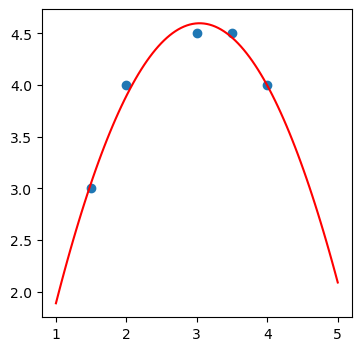

In [74]:
plt.subplots(figsize=(4,4))
xl=np.linspace(1,5,100) 
yl=param[0]+param[1]*xl+param[2]*xl**2
plt.plot(xl,yl,'-r')
plt.scatter(x,y)
plt.show()

---

We can apply the same approach to almost any model. Suppose our model is $y=\beta_0 \cos(x) + \beta_1 \sin(x)$. In this case, 
    $$ X=\begin{bmatrix} \cos(x_1) & \sin(x_1) \\ \vdots & \vdots \\ \cos(x_n) & \sin(x_n)\end{bmatrix}\text{, and } {\boldsymbol{\beta}}=\begin{bmatrix} \beta_0 \\ \beta_1 \end{bmatrix}$$

We can have more than one independent variable. For example, suppose that $u$ and $v$ are independent variables and $y$ is the dependent variable. Then the linear regression model is $$y=\beta_0+\beta_1 u+ \beta_2 v$$ Therefore, in this case 
$$ X=\begin{bmatrix} 1 & u_1 & v_1 \\ \vdots & \vdots & \vdots \\ 1 & u_n & v_n\end{bmatrix}\text{, and } {\boldsymbol{\beta}}=\begin{bmatrix} \beta_0 \\ \beta_1 \\ \beta_2 \end{bmatrix}$$

Or, if we wanted a quadratic regression model, then $$y=\beta_0+\beta_1 u+ \beta_2 v + \beta_3u^2+\beta_4 v^2+ \beta_5 uv$$ And so, in this case,
$$ X=\begin{bmatrix} 1 & u_1 & v_1 & u_1^2 & v_1^2 & u_1v_1 \\ \vdots & \vdots & \vdots & \vdots & \vdots & \vdots\\ 1 & u_n & v_n & u_n^2 & v_n^2 & u_nv_n \end{bmatrix}\text{, and } {\boldsymbol{\beta}}=\begin{bmatrix} \beta_0 \\ \beta_1 \\ \beta_2 \\ \beta_3 \\ \beta_4 \\ \beta_5\end{bmatrix}$$

After we set up $X$, ${\boldsymbol{\beta}}$ and $\bf y$, we proceed to calculate the least-squares solution.

We can also have multiple dependent variables. In this case, we represent the outcomes using a matrix $Y$ rather than a vector ${\bf y}$. Likewise, instead of an unknown parameter vector ${\boldsymbol{\beta}}$, we have a parameter matrix $B$. Each column of $Y$ (and the corresponding column of $B$) represents one dependent variable. The least-squares method still applies. For example, if $X$ has linearly independent columns, the least-squares solution is given by $$ \hat{B}=(X^TX)^{-1}X^TY$$ This is equivalent to performing a separate regression for each dependent variable and then combining the results.

######
<font color="#0fbf0f" size="5"><div style="
    font-family: Verdana;
    font-size: 1.6em;
    font-weight: 600;
    line-height: 1.3;
    padding: 0.5em 1em;
    margin: 0.5em 0 0.6em 0;
    border-top: 2px solid rgba(144,62,80,0.3);
    border-bottom: 2px solid rgba(144,62,80,0.3);
    border-radius: 8px;
">
<b>Exercises</b>
</div></font> 

**1.** 
>Find the best approximation of $\bf v$ in the subspace $W=span({\bf u}_1, {\bf u}_2)$. The vectors ${\bf u}_1$ and $ {\bf u}_2$ are orthogonal. <br><br>
>***a.*** ${\bf u}_1=\begin{bmatrix} 1 \\ 2 \\-1\end{bmatrix}$, ${\bf u}_2=\begin{bmatrix} -1 \\  1 \\ 1 \end{bmatrix}$, ${\bf v}=\begin{bmatrix} 2 \\  1 \\ 0 \end{bmatrix};$ <br><br>
>***b.*** ${\bf u}_1=\begin{bmatrix} 2 \\ 1 \\ -2\end{bmatrix}$, ${\bf u}_2=\begin{bmatrix} 0 \\  4 \\ 2 \end{bmatrix}$, ${\bf v}=\begin{bmatrix} -2 \\  3 \\ 4 \end{bmatrix};$ <br><br>
>***c.*** ${\bf u}_1=\begin{bmatrix} -1 \\ 3 \\-1 \\ 1\end{bmatrix}$, ${\bf u}_2=\begin{bmatrix} 2 \\  1 \\ 0 \\ -1 \end{bmatrix}$, ${\bf v}=\begin{bmatrix} 0 \\  4 \\ 0 \\ 2\end{bmatrix}$. <br><br>



**2.**  
>In Problem 1, find the distance between ${\bf v}$ and the subspace $W$.

**3.**  
>***a.*** Let $X= \begin{bmatrix} 5 & 9 \\ 1 & 7 \\ -3 & -5 \\ 1 & 5 \end{bmatrix}$ and ${\bf y} =\begin{bmatrix} 1 \\ 2 \\ -2 \\ 0 \end{bmatrix}$. Find a least-squares solution to  $X{\boldsymbol{\beta}}={\bf y}$. <br><br>
>***b.*** Let $A= \begin{bmatrix} 1 & 2 \\ 1 & -3 \\ 0 & 4 \end{bmatrix}$ and ${\bf b} =\begin{bmatrix} 3 \\ 2 \\ -2 \end{bmatrix}$. Find a least-squares solution to $A{\bf x}={\bf b}$.

**4.** 
>Let $A= \begin{bmatrix} 1 & 2 \\ -1 & -2 \\ 2 & 4 \end{bmatrix}$ and ${\bf b} =\begin{bmatrix} 2 \\ 2 \\ 0 \end{bmatrix}$.<br><br>
>***a.*** Describe all least-squares solutions of $A{\bf x}={\bf b}$<br>
>***b.*** Express the least-squares solutions $\hat{\bf x}$ in parametric form. Find $A\hat{\bf x}$ to verify that there is a unique least-squares approximation of ${\bf b}$ in $Col(A)$.

**5.**
> Let $A= \begin{bmatrix} 5 & 9 \\ 1 & 7 \\ -3 & -5 \\ 1 & 5 \end{bmatrix}$, $Q =\begin{bmatrix} 5/6 & -1/6 \\ 1/6 & 5/6 \\ -3/6 & 1/6 \\ 1/6 & 3/6 \end{bmatrix}$ and  ${\bf b}=\begin{bmatrix} 1 \\ 2 \\ -2 \\ 0 \end{bmatrix}$. <br><br>
> ***a.*** Use the QR factorization $A=QR$ to find the least-squares solution to $A{\bf x}={\bf b}$. (Hint: Refer to Exercise 3 in Chapter 4.3 for matrix $R$.)<br>
> ***b.*** Repeat this problem using Python.

**6.**
> Find the equation $y=\beta_0+\beta_1x$ of the best-fit line for the following data points: $(1,3), (1, 4), (2,4), (3,6)$. Using this least-squares line, what is the predicted value of $y$ when $x=2$?

**7.**
> Find the equation $y=\beta_0x+\beta_1x^2$ of the best-fit curve for the following data points: $(1,3), (2, 4), (3,3), (4,1)$. (Warning: Be careful when constructing the matrix $X$). Using this least-squares curve, what is the predicted value of $y$ when $x=2$?

**8.** 
> Using Python, find the equation $y=\beta_0+\beta_1\ln(x)$ of the best-fit curve for the following data points: $(1, 1), (2 ,6), (3, 8), (4,9), (5, 10)$. Use the QR factorization method.

**9.** 
> Using Python, find the equation $y=\beta_0+\beta_1u+\beta_2v$ of the best-fit plane for the following data points:
<table>
      <tr>
        <td><strong>$(u,v)$ </strong> </td>
        <td><strong>$y$ </strong></td>
      </tr>
      <tr>
        <td>(1,0) </td>
        <td>1</td>
      </tr>
      <tr>
        <td>(0,3) </td>
        <td>2</td>
      </tr>
      <tr>
        <td>(2,3) </td>
        <td>4</td>
      </tr> 
      <tr>
        <td>(2,1) </td>
        <td>2</td>
      </tr> 
</table>

> Using this least-squares line, what is the predicted value of $y$ when $u=2$ and $v=2$?

**10.**
> Upload the dataset "Performance Set.csv". It contains information about 20 students: number of hours they spend studying per week, attendance percentage, and number of projects completed.<br>
> ***a.*** Standardize the features of the dataset.<br>
> ***b.*** Find a linear regression model that uses study hours and attendance to predict the number of projects completed.<br>
> ***c.*** How many projects does the model predict a student will complete if that student spends 10 hours a week studying and attends 70% of the classes? (Caution: When making predictions, remember to standardize the new input values using the means and standard deviations from the original dataset, and then undo standardization of the outcome.)<br>
> ***d.*** What is the total error for this model?